# Economics S5040 — Problem Set 4
## Answer Key

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Problem 1

The state is $k_t$, the control is $k_{t+1}$, the reward is
$\log(Ak_t^\alpha-k_{t+1})$, the transition rule is $k_{t+1}$ itself,
and the discount factor is $\beta$.

The Bellman equation is
$$
V(k_t)=\max_{k_{t+1}}
\left\{\log(Ak_t^\alpha-k_{t+1})+\beta V(k_{t+1})\right\}.
$$

The FOC is
$$
\frac{1}{c_t}=\beta V'(k_{t+1}).
$$
Using the envelope condition
$$
V'(k_{t+1})=u'(c_{t+1})f'(k_{t+1})
$$
gives the Euler equation
$$
u'(c_t)=\beta u'(c_{t+1})f'(k_{t+1}).
$$

Guessing $V(k)=E+F\log k$ yields
$$
F=\frac{\alpha}{1-\alpha\beta},
\qquad
k_{t+1}=\alpha\beta A k_t^\alpha.
$$


0.8 0.4098236006280099 0.4098236006280099
0.95 0.533848363634239 0.5338483636342389
0.99 0.5688191474676395 0.5688191474676395


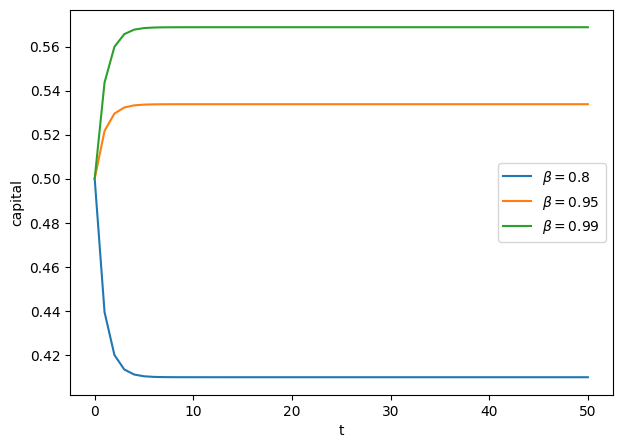

In [10]:
A = 2.0
alpha = 0.35

def optimal_capital_path(A, alpha, beta, k0, T):
    path = np.empty(T+1)
    path[0] = k0
    for t in range(T):
        path[t+1] = alpha * beta * A * path[t]**alpha
    return path

def k_star(A, alpha, beta):
    return (alpha * beta * A)**(1/(1-alpha))

plt.figure(figsize=(7,5))
for beta in [0.80, 0.95, 0.99]:
    path = optimal_capital_path(A, alpha, beta, .5, 50)
    plt.plot(path, label=fr"$\beta={beta}$")
    print(beta, k_star(A, alpha, beta), path[-1])
plt.xlabel("t")
plt.ylabel("capital")
plt.legend()
plt.show()


Greater patience raises the optimal saving rate $\alpha\beta$, which raises the steady-state capital stock.

# Problem 2

In [3]:
states = ['Sick', 'Okay', 'Great']
controls = ['TV', 'Study']

R_student = np.array([[1., -1.],
                      [2.,  1.],
                      [8.,  5.]])

M_tv = np.array([[.5,.5,0],
                 [.1,.4,.5],
                 [0,.4,.6]])
M_study = np.array([[.9,.1,0],
                    [.3,.6,.1],
                    [.3,.6,.1]])
transitions = [M_tv, M_study]
beta = .5

# Evaluate all-TV policy
policy0 = np.array([0,0,0])
r_h = R_student[np.arange(3), policy0]
P_h = np.vstack([transitions[policy0[s]][s] for s in range(3)])
V_h = np.linalg.solve(np.eye(3)-beta*P_h, r_h)
print("V all-TV =", V_h)

# One Howard improvement
Q = np.empty((3,2))
for s in range(3):
    for a in range(2):
        Q[s,a] = R_student[s,a] + beta * transitions[a][s] @ V_h
print("Q =\n", Q)
print("Improved policy =", [controls[i] for i in Q.argmax(axis=1)])


V all-TV = [ 3.63879599  6.91638796 13.40468227]
Q =
 [[ 3.63879599  0.98327759]
 [ 6.91638796  4.2909699 ]
 [13.40468227  8.2909699 ]]
Improved policy = ['TV', 'TV', 'TV']


In [4]:
def bellman(V, R, transitions, beta):
    Q = np.empty((R.shape[0], R.shape[1]))
    for s in range(R.shape[0]):
        for a in range(R.shape[1]):
            Q[s,a] = R[s,a] + beta * transitions[a][s] @ V
    return Q.max(axis=1), Q.argmax(axis=1)

V = np.zeros(3)
for it in range(10000):
    Vn, pol = bellman(V, R_student, transitions, beta)
    if np.max(np.abs(Vn-V)) < 1e-10:
        V = Vn
        break
    V = Vn

print("iterations =", it+1)
print("V* =", V)
print("policy =", [controls[i] for i in pol])

Popt = np.vstack([transitions[pol[s]][s] for s in range(3)])
print("Popt =\n", Popt)

def stationary_distribution(P):
    n = P.shape[0]
    A = P.T - np.eye(n)
    A[-1,:] = 1
    b = np.zeros(n); b[-1] = 1
    return np.linalg.solve(A,b)

print("stationary =", stationary_distribution(Popt))


iterations = 37
V* = [ 3.63879599  6.91638796 13.40468227]
policy = ['TV', 'TV', 'TV']
Popt =
 [[0.5 0.5 0. ]
 [0.1 0.4 0.5]
 [0.  0.4 0.6]]
stationary = [0.08163265 0.40816327 0.51020408]


Howard improvement and VFI solve the same Bellman fixed point. Howard iterates over policies, while VFI iterates over value functions.

# Problem 3

In [5]:
States = ['Bad','Normal','Good']
Controls = ['No Buy','Buy']
reward = np.array([[1.,0.],[2.,1.],[4.,3.]])
M0 = np.array([[.8,.2,0],[.2,.8,0],[.1,.4,.5]])
M1 = np.array([[.5,.5,0],[.1,.6,.3],[.1,.3,.6]])
transition = {'No Buy':M0,'Buy':M1}
beta=.9

def check_dp(V, reward, transition, beta):
    n = len(V)
    assert reward.shape == (n, len(transition))
    assert 0 < beta < 1
    for P in transition.values():
        assert P.shape == (n,n)
        assert np.all(P >= 0)
        assert np.allclose(P.sum(axis=1), 1)
    return True

def get_transition(state, control, transition):
    s = States.index(state) if isinstance(state,str) else state
    return transition[control][s]

def update_value(V, States, Controls, reward, transition, beta):
    Q = np.empty((len(States),len(Controls)))
    for s,state in enumerate(States):
        for a,control in enumerate(Controls):
            Q[s,a] = reward[s,a] + beta * transition[control][s] @ V
    return Q.max(axis=1)

def solve_value(V0, States, Controls, reward, transition, beta,
                tol=1e-10, max_iter=10000):
    V = V0.copy()
    for it in range(max_iter):
        Vn = update_value(V, States, Controls, reward, transition, beta)
        if np.max(np.abs(Vn-V)) < tol:
            return Vn, it+1
        V = Vn
    raise RuntimeError("No convergence")

def optimal_policy(V, States, Controls, reward, transition, beta):
    policy=[]
    for s in range(len(States)):
        vals=[reward[s,a] + beta*transition[c][s]@V
              for a,c in enumerate(Controls)]
        policy.append(Controls[int(np.argmax(vals))])
    return policy

def policy_transition(policy, States, transition):
    return np.vstack([transition[policy[s]][s] for s in range(len(States))])

def stationary_distribution(P):
    n=P.shape[0]
    A=P.T-np.eye(n)
    A[-1,:]=1
    b=np.zeros(n); b[-1]=1
    return np.linalg.solve(A,b)

V,its = solve_value(np.zeros(3), States, Controls, reward, transition, beta)
policy = optimal_policy(V, States, Controls, reward, transition, beta)
Pstar = policy_transition(policy, States, transition)
pi = stationary_distribution(Pstar)

print("V =",V)
print("iterations =",its)
print("policy =",policy)
print("P* =\n",Pstar)
print("pi =",pi)

df = pd.DataFrame({
    'Reward: No Buy': reward[:,0],
    'Reward: Buy': reward[:,1],
    'Value': V,
    'Optimal Policy': policy,
    'Ergodic Probability': pi
}, index=States)
df


V = [14.80553724 17.47528016 21.13381674]
iterations = 225
policy = ['No Buy', 'Buy', 'No Buy']
P* =
 [[0.8 0.2 0. ]
 [0.1 0.6 0.3]
 [0.1 0.4 0.5]]
pi = [0.33333333 0.41666667 0.25      ]


,Reward: No Buy,Reward: Buy,Value,Optimal Policy,Ergodic Probability
Bad,1.0,0.0,14.805537,No Buy,0.333333
Normal,2.0,1.0,17.475280,Buy,0.416667
Good,4.0,3.0,21.133817,No Buy,0.250000


The optimal policy is

$$
(\text{Bad},\text{Normal},\text{Good})
=
(\text{No Buy},\text{Buy},\text{No Buy}).
$$

The approximate value function is
$$
(14.806,\;17.475,\;21.134),
$$
and the stationary distribution under the optimal policy is
$$
(1/3,\;5/12,\;1/4).
$$


In [6]:
class DP_Markov:
    def __init__(self, States, Controls, reward, transition, beta):
        self.States = States
        self.Controls = Controls
        self.reward = np.asarray(reward, float)
        self.transition = transition
        self.beta = beta
        self.V0 = np.zeros(len(States))
        check_dp(self.V0, self.reward, self.transition, self.beta)

    def update(self, V):
        return update_value(V, self.States, self.Controls,
                            self.reward, self.transition, self.beta)

    def solve(self, tol=1e-10, max_iter=10000):
        self.V, self.iterations = solve_value(
            self.V0, self.States, self.Controls,
            self.reward, self.transition, self.beta,
            tol, max_iter)
        self.policy = optimal_policy(
            self.V, self.States, self.Controls,
            self.reward, self.transition, self.beta)
        self.P_policy = policy_transition(
            self.policy, self.States, self.transition)
        self.pi = stationary_distribution(self.P_policy)
        return self.V

    def dataframe(self):
        return pd.DataFrame({
            'Reward: No Buy': self.reward[:,0],
            'Reward: Buy': self.reward[:,1],
            'Value': self.V,
            'Optimal Policy': self.policy,
            'Ergodic Probability': self.pi
        }, index=self.States)

dp = DP_Markov(States, Controls, reward, transition, beta)
dp.solve()
dp.dataframe()


,Reward: No Buy,Reward: Buy,Value,Optimal Policy,Ergodic Probability
Bad,1.0,0.0,14.805537,No Buy,0.333333
Normal,2.0,1.0,17.475280,Buy,0.416667
Good,4.0,3.0,21.133817,No Buy,0.250000


# Problem 4

In [7]:
sales = np.array([1.,2.,4.])
net_reward_under_policy = np.array([
    reward[s, Controls.index(policy[s])] for s in range(3)
])

print("Long-run average sales =", pi @ sales)
print("Long-run average net one-period reward =", pi @ net_reward_under_policy)


Long-run average sales = 2.1666666666666665
Long-run average net one-period reward = 1.75


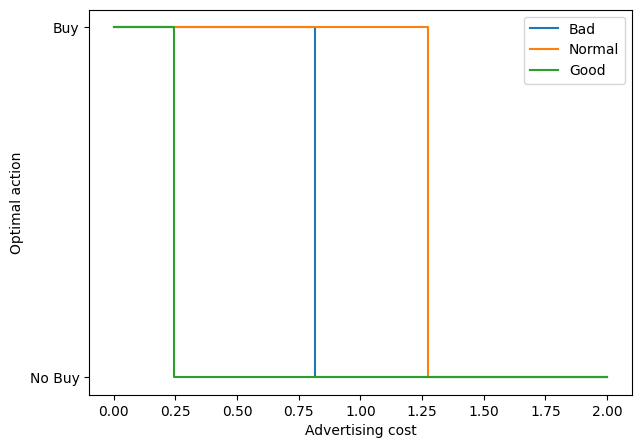

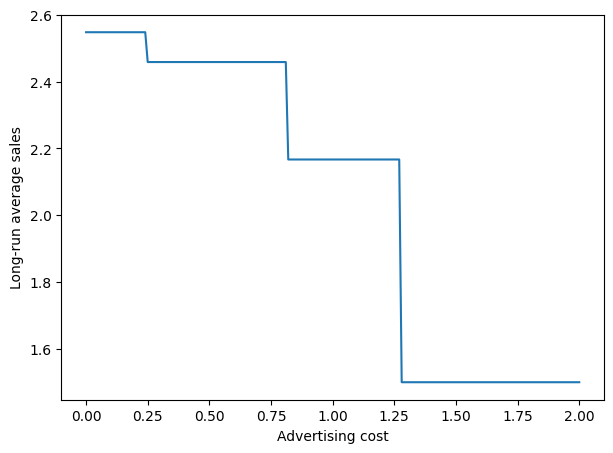

In [8]:
def solve_ad_model(cost=1.0, beta=.9):
    R = np.column_stack([sales, sales-cost])
    V,_ = solve_value(np.zeros(3), States, Controls, R, transition, beta)
    pol = optimal_policy(V, States, Controls, R, transition, beta)
    Pp = policy_transition(pol, States, transition)
    pip = stationary_distribution(Pp)
    return V, pol, Pp, pip

cost_grid = np.linspace(0,2,201)
policy_codes = np.empty((len(cost_grid),3), dtype=int)
long_run_sales = np.empty(len(cost_grid))

for i,c in enumerate(cost_grid):
    _,p,_,pic = solve_ad_model(cost=c,beta=.9)
    policy_codes[i] = [Controls.index(x) for x in p]
    long_run_sales[i] = pic @ sales

plt.figure(figsize=(7,5))
for s,name in enumerate(States):
    plt.step(cost_grid, policy_codes[:,s], where='mid', label=name)
plt.yticks([0,1], ['No Buy','Buy'])
plt.xlabel("Advertising cost")
plt.ylabel("Optimal action")
plt.legend()
plt.show()

plt.figure(figsize=(7,5))
plt.plot(cost_grid,long_run_sales)
plt.xlabel("Advertising cost")
plt.ylabel("Long-run average sales")
plt.show()


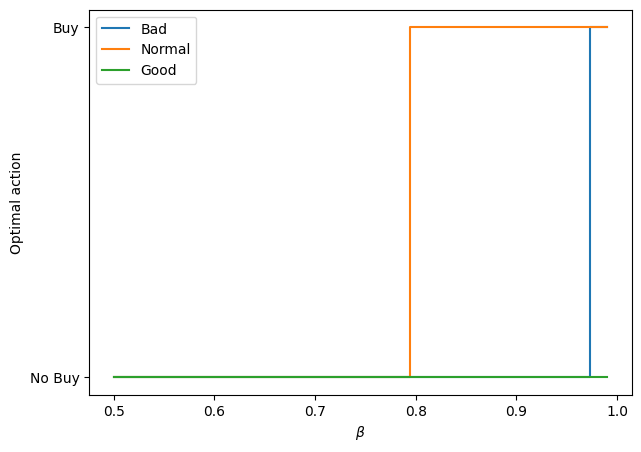

In [9]:
beta_grid=np.linspace(.50,.99,100)
policy_beta=np.empty((len(beta_grid),3),dtype=int)

for i,b in enumerate(beta_grid):
    _,p,_,_ = solve_ad_model(cost=1.0,beta=b)
    policy_beta[i]=[Controls.index(x) for x in p]

plt.figure(figsize=(7,5))
for s,name in enumerate(States):
    plt.step(beta_grid,policy_beta[:,s],where='mid',label=name)
plt.yticks([0,1],['No Buy','Buy'])
plt.xlabel(r"$\beta$")
plt.ylabel("Optimal action")
plt.legend()
plt.show()


Advertising sacrifices current profit in exchange for a more favorable distribution of future states. A one-period expected-sales rule is generally wrong because the Bellman equation values the entire future path, not merely next year's expected sales. Policy changes can cause jumps in long-run outcomes because a small parameter change can switch the optimal action in a state, thereby changing an entire row of the induced transition matrix.

# Problem 5 — Sample synthesis

A strong answer should clearly distinguish the state from the control, the reward from the continuation value, and the value function from the policy function. It should explain that the Bellman equation reduces an infinite-horizon problem to a one-period choice because the value function summarizes all future optimal opportunities. VFI iterates on guesses of the value function; Howard improvement iterates on guesses of the policy.

# What surprised me?

Student-specific response.